# Feature-noise data poisoning

Парное сравнение FedAvg на MNIST без атаки и с гауссовым шумом в локальных изображениях вредоносных клиентов. Метки не изменяются.

In [5]:
import json, os, sys
from dataclasses import replace
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'pyproject.toml').exists():
    PROJECT_ROOT = next(path for path in [PROJECT_ROOT, *PROJECT_ROOT.parents] if (path / 'pyproject.toml').exists())
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT / 'src')) if str(PROJECT_ROOT / 'src') not in sys.path else None
from fl_benchmark.attacks.label_flip import build_label_flip_plan, make_client_dataset
from fl_benchmark.config import load_config
from fl_benchmark.datasets.loader import load_datasets
from fl_benchmark.datasets.partitioning import create_partitions, get_targets
from fl_benchmark.task import run_local_simulation

base = load_config(PROJECT_ROOT / 'configs' / 'mnist_feature_noise.toml')
NOTEBOOK_RESULTS_DIR = PROJECT_ROOT / 'notebooks' / 'results'
REPORT_PICS_DIR = PROJECT_ROOT / 'practice_report' / 'pics'
NOTEBOOK_RESULTS_DIR.mkdir(parents=True, exist_ok=True); REPORT_PICS_DIR.mkdir(parents=True, exist_ok=True)
clean = replace(base, name='mnist-feature-noise-clean-control', attack=replace(base.attack, enabled=False, type='none', malicious_fraction=0.0, poison_fraction=0.0), tracking=replace(base.tracking, output_dir=NOTEBOOK_RESULTS_DIR, experiment_name='mnist-feature-noise-clean-control'), source_path=None)
attack = replace(base, name='mnist-feature-noise-attack', tracking=replace(base.tracking, output_dir=NOTEBOOK_RESULTS_DIR, experiment_name='mnist-feature-noise-attack'), source_path=None)
pd.DataFrame([('Атака', 'Gaussian feature noise'), ('Шум, std', attack.attack.noise_std), ('Вредоносные клиенты', f'{attack.attack.malicious_fraction:.0%}'), ('Доля зашумлённых образцов', f'{attack.attack.poison_fraction:.0%}')], columns=['Параметр','Значение'])

,Параметр,Значение
0,Атака,Gaussian feature noise
1,"Шум, std",0.75
2,Вредоносные клиенты,20%
3,Доля зашумлённых образцов,50%


## Визуальная проверка атаки

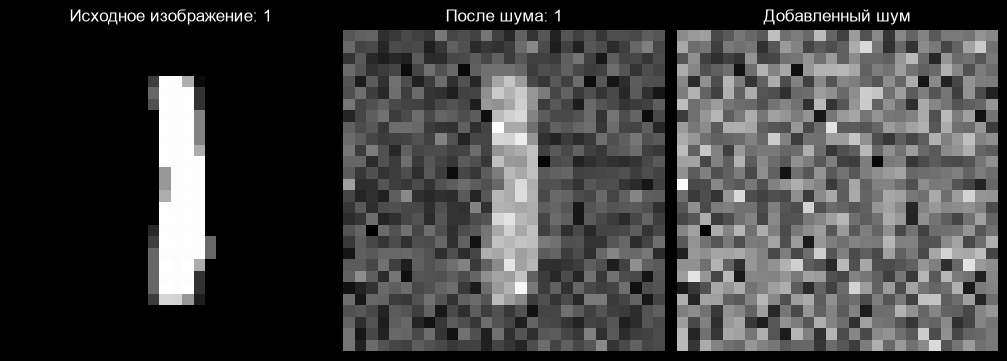

Вредоносные клиенты: (0, 7) | зашумлённые примеры: 4623


In [6]:
bundle = load_datasets(attack.dataset)
partitions = create_partitions(bundle.train, attack.partition)
plan = build_label_flip_plan(get_targets(bundle.train), partitions, attack.attack)
client_id = plan.malicious_clients[0]
local = make_client_dataset(bundle.train, partitions[client_id], plan, client_id)
sample_index = next(i for i, global_index in enumerate(partitions[client_id]) if global_index in plan.poisoned_indices[client_id])
original, label = bundle.train[partitions[client_id][sample_index]]
noisy, noisy_label = local[sample_index]
fig, axes = plt.subplots(1, 3, figsize=(10, 3.5), constrained_layout=True)
for axis, image, title in [(axes[0], original, f'Исходное изображение: {label}'), (axes[1], noisy, f'После шума: {noisy_label}'), (axes[2], noisy-original, 'Добавленный шум')]:
    axis.imshow(image.squeeze(), cmap='gray'); axis.set_title(title); axis.axis('off')
fig.savefig(REPORT_PICS_DIR / '06_feature_noise_comparison_example.png', dpi=200, bbox_inches='tight')
plt.show()
print('Вредоносные клиенты:', plan.malicious_clients, '| зашумлённые примеры:', plan.total_poisoned_examples)

## Полный парный запуск

Поставьте `False`, чтобы повторно построить сравнение по уже сохранённым результатам без обучения.

In [7]:
RUN_FULL_EXPERIMENTS = False
def latest(prefix):
    paths = sorted(NOTEBOOK_RESULTS_DIR.glob(f'{prefix}-*'), key=lambda path: path.stat().st_mtime)
    if not paths: raise FileNotFoundError(prefix)
    return paths[-1]
if RUN_FULL_EXPERIMENTS:
    clean_dir = run_local_simulation(clean)
    attack_dir = run_local_simulation(attack)
else:
    clean_dir, attack_dir = latest('mnist-feature-noise-clean-control'), latest('mnist-feature-noise-attack')
print(clean_dir, attack_dir, sep='\n')

C:\Users\neko\Desktop\projects\fed-learning-stand\notebooks\results\mnist-feature-noise-clean-control-20261125-145310-8b486e78
C:\Users\neko\Desktop\projects\fed-learning-stand\notebooks\results\mnist-feature-noise-attack-20261125-145541-83d9339b


## Сравнение результатов

,Метрика,Контроль,Feature noise,Разность
0,Final accuracy,0.973100,0.972900,-0.00020
1,Final loss,0.085004,0.085364,0.00036
2,Macro F1,0.972849,0.972639,-0.00021
3,Отравлённых примеров,0.000000,4623.000000,4623.00000


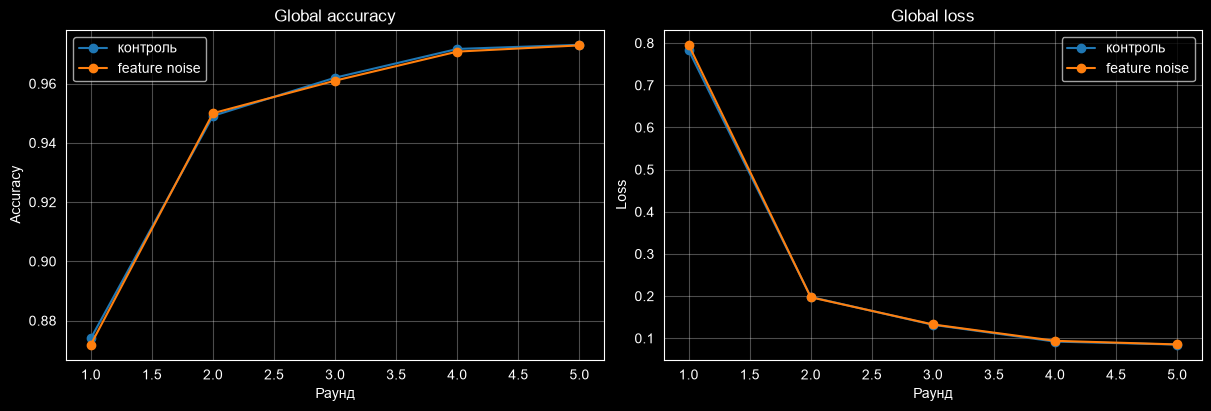

,class_id,support,accuracy_control,accuracy_feature_noise,accuracy_delta_pp,loss_control,loss_feature_noise,loss_delta
0,0,980,0.9959,0.9949,-0.1020,0.0271,0.0287,0.0016
1,1,1135,0.9956,0.9965,0.0881,0.0229,0.0192,-0.0037
2,2,1032,0.9777,0.9729,-0.4845,0.0542,0.0633,0.0092
3,3,1010,0.9782,0.9772,-0.0990,0.0719,0.0772,0.0053
4,4,982,0.9796,0.9817,0.2037,0.0609,0.0545,-0.0064
5,5,892,0.9798,0.9843,0.4484,0.0709,0.0675,-0.0034
6,6,958,0.9864,0.9864,0.0000,0.0343,0.0361,0.0018
7,7,1028,0.9630,0.9669,0.3891,0.0942,0.0908,-0.0034
8,8,974,0.9148,0.9117,-0.3080,0.2742,0.2711,-0.0031
9,9,1009,0.9574,0.9544,-0.2973,0.1478,0.1531,0.0053


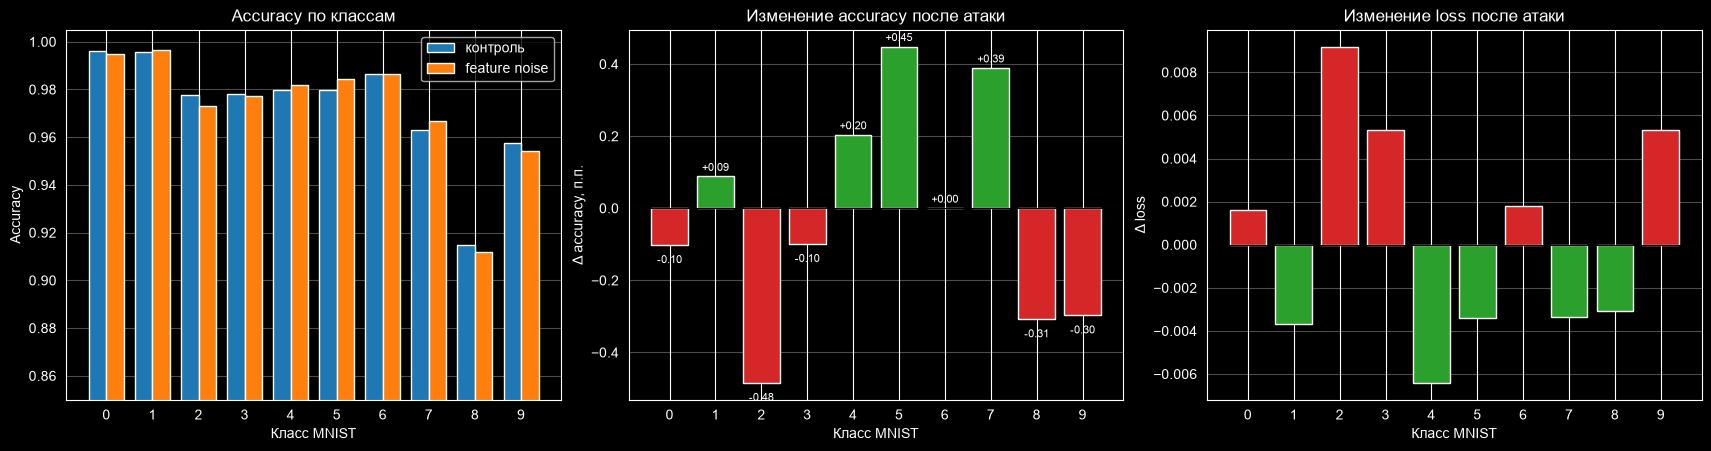

Сохранён поклассовый график: C:\Users\neko\Desktop\projects\fed-learning-stand\practice_report\pics\06_feature_noise_comparison_per_class_effect.png


In [8]:
def load_run(path):
    return (
        json.loads((path / 'summary.json').read_text(encoding='utf-8')),
        pd.read_csv(path / 'round_metrics.csv'),
        pd.read_csv(path / 'final_per_class_metrics.csv'),
    )
clean_summary, clean_rounds, clean_per_class = load_run(clean_dir)
attack_summary, attack_rounds, attack_per_class = load_run(attack_dir)
comparison = pd.DataFrame([('Final accuracy', clean_summary['final_accuracy'], attack_summary['final_accuracy']), ('Final loss', clean_summary['final_loss'], attack_summary['final_loss']), ('Macro F1', clean_summary['final_macro_f1'], attack_summary['final_macro_f1']), ('Отравлённых примеров', 0, attack_summary['total_poisoned_examples'])], columns=['Метрика','Контроль','Feature noise'])
comparison['Разность'] = comparison['Feature noise'] - comparison['Контроль']
display(comparison)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for rounds, label, color in [(clean_rounds, 'контроль', 'tab:blue'), (attack_rounds, 'feature noise', 'tab:orange')]:
    axes[0].plot(rounds['round'], rounds['global_accuracy'], marker='o', label=label, color=color)
    axes[1].plot(rounds['round'], rounds['global_loss'], marker='o', label=label, color=color)
for axis, title, ylabel in [(axes[0], 'Global accuracy', 'Accuracy'), (axes[1], 'Global loss', 'Loss')]:
    axis.set(title=title, xlabel='Раунд', ylabel=ylabel); axis.grid(alpha=.3); axis.legend()
fig.savefig(REPORT_PICS_DIR / '06_feature_noise_comparison_learning_curves.png', dpi=200, bbox_inches='tight')
plt.show()

# Поклассовый эффект: отрицательная дельта означает ухудшение после атаки.
per_class = clean_per_class.merge(attack_per_class, on=['class_id', 'support'], suffixes=('_control', '_feature_noise'))
per_class['accuracy_delta_pp'] = (per_class['accuracy_feature_noise'] - per_class['accuracy_control']) * 100
per_class['loss_delta'] = per_class['loss_feature_noise'] - per_class['loss_control']
display(per_class[['class_id', 'support', 'accuracy_control', 'accuracy_feature_noise', 'accuracy_delta_pp', 'loss_control', 'loss_feature_noise', 'loss_delta']].round(4))

classes = per_class['class_id'].to_numpy()
width = 0.38
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4), constrained_layout=True)
axes[0].bar(classes - width / 2, per_class['accuracy_control'], width, label='контроль', color='tab:blue')
axes[0].bar(classes + width / 2, per_class['accuracy_feature_noise'], width, label='feature noise', color='tab:orange')
axes[0].set(title='Accuracy по классам', xlabel='Класс MNIST', ylabel='Accuracy', xticks=classes, ylim=(0.85, 1.005))
axes[0].grid(axis='y', alpha=.3); axes[0].legend()

delta_colors = np.where(per_class['accuracy_delta_pp'] < 0, 'tab:red', 'tab:green')
axes[1].bar(classes, per_class['accuracy_delta_pp'], color=delta_colors)
axes[1].axhline(0, color='black', linewidth=.8)
axes[1].set(title='Изменение accuracy после атаки', xlabel='Класс MNIST', ylabel='Δ accuracy, п.п.', xticks=classes)
axes[1].grid(axis='y', alpha=.3)
for class_id, delta in zip(classes, per_class['accuracy_delta_pp']):
    axes[1].annotate(f'{delta:+.2f}', (class_id, delta), xytext=(0, 4 if delta >= 0 else -13), textcoords='offset points', ha='center', fontsize=8)

loss_colors = np.where(per_class['loss_delta'] > 0, 'tab:red', 'tab:green')
axes[2].bar(classes, per_class['loss_delta'], color=loss_colors)
axes[2].axhline(0, color='black', linewidth=.8)
axes[2].set(title='Изменение loss после атаки', xlabel='Класс MNIST', ylabel='Δ loss', xticks=classes)
axes[2].grid(axis='y', alpha=.3)
fig.savefig(REPORT_PICS_DIR / '06_feature_noise_comparison_per_class_effect.png', dpi=200, bbox_inches='tight')
plt.show()
print('Сохранён поклассовый график:', REPORT_PICS_DIR / '06_feature_noise_comparison_per_class_effect.png')